In [3]:
!pip install -q qiskit qiskit-aer matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 93.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.6 MB/s eta 0:00:00


**Easy**

In [6]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

n = 3
qc = QuantumCircuit(n + 1, n)

# Prepare output qubit
qc.x(n)

# Apply Hadamard gates
for i in range(n + 1):
    qc.h(i)

# Constant oracle f(x) = 0
# No operation required

# Final Hadamard gates on input qubits
for i in range(n):
    qc.h(i)

qc.measure(range(n), range(n))

print(qc.draw())

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
print(result.get_counts())

     ┌───┐┌───┐┌─┐      
q_0: ┤ H ├┤ H ├┤M├──────
     ├───┤├───┤└╥┘┌─┐   
q_1: ┤ H ├┤ H ├─╫─┤M├───
     ├───┤├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├┤ H ├─╫──╫─┤M├
     ├───┤├───┤ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─╫──╫──╫─
     └───┘└───┘ ║  ║  ║ 
c: 3/═══════════╩══╩══╩═
                0  1  2 
{'000': 1024}


**Medium**

In [7]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

n = 3
qc = QuantumCircuit(n + 1, n)

qc.x(n)

for i in range(n + 1):
    qc.h(i)

# Balanced parity oracle
for i in range(n):
    qc.cx(i, n)

for i in range(n):
    qc.h(i)

qc.measure(range(n), range(n))

print(qc.draw())

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
print(result.get_counts())

     ┌───┐          ┌───┐     ┌─┐           
q_0: ┤ H ├───────■──┤ H ├─────┤M├───────────
     ├───┤       │  └───┘┌───┐└╥┘     ┌─┐   
q_1: ┤ H ├───────┼────■──┤ H ├─╫──────┤M├───
     ├───┤       │    │  └───┘ ║ ┌───┐└╥┘┌─┐
q_2: ┤ H ├───────┼────┼────■───╫─┤ H ├─╫─┤M├
     ├───┤┌───┐┌─┴─┐┌─┴─┐┌─┴─┐ ║ └───┘ ║ └╥┘
q_3: ┤ X ├┤ H ├┤ X ├┤ X ├┤ X ├─╫───────╫──╫─
     └───┘└───┘└───┘└───┘└───┘ ║       ║  ║ 
c: 3/══════════════════════════╩═══════╩══╩═
                               0       1  2 
{'111': 1024}


**Hard**

In [8]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def deutsch_jozsa(n, function_type):
    qc = QuantumCircuit(n + 1, n)

    qc.x(n)

    for i in range(n + 1):
        qc.h(i)

    # Oracle
    if function_type == "constant":
        pass
    elif function_type == "balanced":
        for i in range(n):
            qc.cx(i, n)
    else:
        raise ValueError("Choose constant or balanced")

    for i in range(n):
        qc.h(i)

    qc.measure(range(n), range(n))
    return qc


simulator = AerSimulator()

for n in range(2, 6):
    for kind in ["constant", "balanced"]:
        qc = deutsch_jozsa(n, kind)
        result = simulator.run(qc, shots=1024).result()
        print(n, kind, result.get_counts())

2 constant {'00': 1024}
2 balanced {'11': 1024}
3 constant {'000': 1024}
3 balanced {'111': 1024}
4 constant {'0000': 1024}
4 balanced {'1111': 1024}
5 constant {'00000': 1024}
5 balanced {'11111': 1024}


**Real-world**

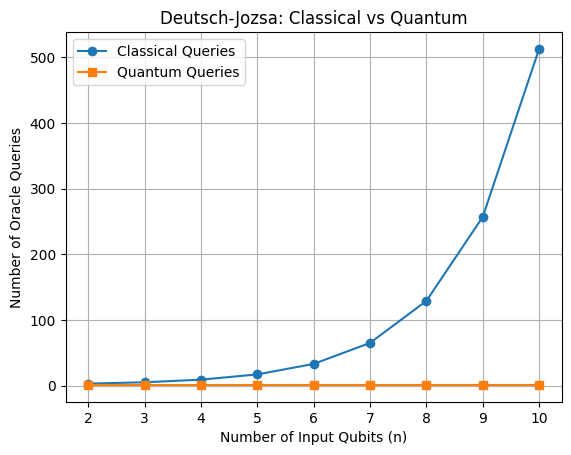

In [9]:
import matplotlib.pyplot as plt

n_values = list(range(2, 11))

# Classical deterministic worst-case queries
classical = [2**(n - 1) + 1 for n in n_values]

# Quantum queries
quantum = [1 for n in n_values]

plt.plot(n_values, classical, marker="o",
         label="Classical Queries")
plt.plot(n_values, quantum, marker="s",
         label="Quantum Queries")

plt.xlabel("Number of Input Qubits (n)")
plt.ylabel("Number of Oracle Queries")
plt.title("Deutsch-Jozsa: Classical vs Quantum")
plt.legend()
plt.grid(True)
plt.show()

**Challenge**

In [10]:
import random
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def random_balanced_oracle(n):
    size = 2**n

    # Select exactly half the inputs as output 1
    table = [0] * size
    for i in random.sample(range(size), size // 2):
        table[i] = 1

    qc = QuantumCircuit(n + 1)

    for index, value in enumerate(table):
        if value == 1:
            bits = format(index, f"0{n}b")

            # Convert zero controls into one controls
            for qubit, bit in enumerate(reversed(bits)):
                if bit == "0":
                    qc.x(qubit)

            qc.mcx(list(range(n)), n)

            # Restore the input qubits
            for qubit, bit in enumerate(reversed(bits)):
                if bit == "0":
                    qc.x(qubit)

    return qc


def run_random_test(n=3):
    qc = QuantumCircuit(n + 1, n)

    qc.x(n)
    for i in range(n + 1):
        qc.h(i)

    oracle = random_balanced_oracle(n)
    qc.compose(oracle, inplace=True)

    for i in range(n):
        qc.h(i)

    qc.measure(range(n), range(n))

    result = AerSimulator().run(qc, shots=1024).result()
    counts = result.get_counts()

    print("Measurement:", counts)
    print("Classification: Balanced" if "0" * n not in counts
          else "Classification failed")


for trial in range(5):
    print(f"\nTrial {trial + 1}")
    run_random_test(3)


Trial 1
Measurement: {'011': 250, '111': 253, '010': 252, '110': 269}
Classification: Balanced

Trial 2
Measurement: {'001': 249, '110': 276, '011': 241, '100': 258}
Classification: Balanced

Trial 3
Measurement: {'101': 253, '001': 278, '111': 262, '011': 231}
Classification: Balanced

Trial 4
Measurement: {'111': 1024}
Classification: Balanced

Trial 5
Measurement: {'010': 266, '001': 275, '101': 231, '110': 252}
Classification: Balanced
